In [5]:
!pip install bioinfokit
!pip install bioinfokit pandas matplotlib numpy

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for bioinfokit: filename=bioinfokit-2.1.4-py3-none-any.whl size=59309 sha256=3fdbaf2ccbf80287f4b0c342586cea3f42270575c77ca64e7a59168cec913e97
  Stored in directory: /root/.cache/pip/wheels/fc/51/ce/c3421fa3b4a59ff5310d04e082636ffde48c5575dba558cd49
Successfully built bioinfokit
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [bioinfokit]


In [6]:
from bioinfokit import analys, visuz
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [11]:
#arq1=r'D:\UEL\rna-seq\6_featureCounts\resultados_DESeq2_all.csv'
#df = pd.read_csv(arq1)


from google.colab import files

uploaded = files.upload()


Saving resultados_DESeq2_all.csv to resultados_DESeq2_all.csv


In [46]:
df = pd.read_csv('resultados_DESeq2_all.csv')
df

,Unnamed: 0,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
0,Dmel_CR40469,32.033722,1.415778,0.390090,3.629366,2.841179e-04,5.654514e-03
1,Dmel_CG17636,1302.291225,0.079334,0.099311,0.798841,4.243826e-01,8.278294e-01
2,Dmel_CG40494,5435.859634,0.096885,0.088590,1.093624,2.741199e-01,6.903453e-01
3,Dmel_CG17131,429.474690,0.065253,0.121923,0.535199,5.925122e-01,9.148918e-01
4,Dmel_CR45473,131.227034,0.474988,0.201546,2.356721,1.843710e-02,1.425802e-01
...,...,...,...,...,...,...,...
15096,Dmel_CG34089,403.377927,-1.736107,0.696492,-2.492644,1.267959e-02,1.093379e-01
15097,Dmel_CG34090,21431.177750,0.136496,0.097550,1.399242,1.617403e-01,5.378334e-01
15098,Dmel_CG34092,2947.451971,-0.175525,0.125278,-1.401084,1.611890e-01,5.368941e-01
15099,Dmel_CR34094,264369.129231,1.109381,0.148759,7.457586,8.812237e-14,2.671710e-11


In [20]:
# df.iloc[linhas, colunas]
# df.iloc[0:5, 0:3]
# df.iloc[:, 0]
# df.loc[0:4, ['Unnamed: 0', 'log2FoldChange', 'padj']]
# df.loc[df['padj'] < 0.05]
# df.loc[(df['padj'] < 0.05) & (df['log2FoldChange'] > 1)]
# df.loc[(df['padj'] < 0.05) & (df['log2FoldChange'] <-1)]
# print(df.loc[(df['padj'] < 0.05) & (df['log2FoldChange'] < -1)].shape)
# print(df.loc[(df['padj'] < 0.05) & (df['log2FoldChange'] < -1)].shape[0])

In [47]:
print(df[['log2FoldChange', 'padj']].isna().sum())
df.loc[df['padj'].isna()]
df = df.dropna(subset=['padj']).reset_index(drop=True) #índices voltam a ser consecutivos

# No DESeq2, isso pode acontecer por três motivos principais:
# 1. Independent filtering: o DESeq2 identifica genes com baixa contagem média (baseMean) e pode atribuir NA ao padj, pois esses genes não apresentam informação suficiente para contribuir com a análise de testes múltiplos.
# 2. Outliers: genes com valores atípicos podem ter seus p-valores e p-valores ajustados definidos como NA.
# 3. P-valor ausente: quando não é possível calcular o p-valor, o padj também fica como NA.

df = df.dropna(subset=['padj'])
print(df[['log2FoldChange', 'padj']].isna().sum())


log2FoldChange       0
padj              1761
dtype: int64
log2FoldChange    0
padj              0
dtype: int64


In [48]:
#1a forma: pelo pacote bioinfokit
visuz.GeneExpression.volcano(df=df, lfc='log2FoldChange', pv='padj', lfc_thr=(1, 1), pv_thr=(0.05, 0.05), plotlegend=True, legendpos='upper right',
    legendanchor=(1.46,1), color=("#00239CFF", "grey", "#E10600FF"))
#Já salva direto no diretório

/usr/local/lib/python3.13/dist-packages/bioinfokit/visuz.py:153: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['color_add_axy'].fillna(color[1], inplace=True)  # intermediate


In [49]:
df

,Unnamed: 0,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
0,Dmel_CR40469,32.033722,1.415778,0.390090,3.629366,2.841179e-04,5.654514e-03
1,Dmel_CG17636,1302.291225,0.079334,0.099311,0.798841,4.243826e-01,8.278294e-01
2,Dmel_CG40494,5435.859634,0.096885,0.088590,1.093624,2.741199e-01,6.903453e-01
3,Dmel_CG17131,429.474690,0.065253,0.121923,0.535199,5.925122e-01,9.148918e-01
4,Dmel_CR45473,131.227034,0.474988,0.201546,2.356721,1.843710e-02,1.425802e-01
...,...,...,...,...,...,...,...
13335,Dmel_CG34089,403.377927,-1.736107,0.696492,-2.492644,1.267959e-02,1.093379e-01
13336,Dmel_CG34090,21431.177750,0.136496,0.097550,1.399242,1.617403e-01,5.378334e-01
13337,Dmel_CG34092,2947.451971,-0.175525,0.125278,-1.401084,1.611890e-01,5.368941e-01
13338,Dmel_CR34094,264369.129231,1.109381,0.148759,7.457586,8.812237e-14,2.671710e-11


In [50]:
#2a forma: mais "manual" - Melhor
listapval_inferior=[]
listapval_superior=[]
listaFC_inferior=[]
listaFC_superior=[]

limite_inferior = -1
limite_superior = 1

limite_infeiorp=0.05

for i in range (len(df)):
    if df['log2FoldChange'][i]<=limite_inferior and df['padj'][i]<=limite_infeiorp:
        listapval_inferior.append(df['padj'][i])
        listaFC_inferior.append(df['log2FoldChange'][i])
    if df['log2FoldChange'][i]>=limite_superior and df['padj'][i]<=limite_infeiorp:
        listapval_superior.append(df['padj'][i])
        listaFC_superior.append(df['log2FoldChange'][i])

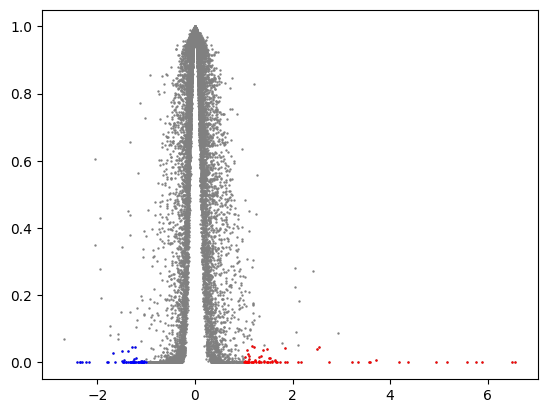

In [52]:
plt.scatter(df['log2FoldChange'], df['padj'], c="gray", s=0.5)
plt.scatter(listaFC_inferior, listapval_inferior, c="blue", s=0.5)
plt.scatter(listaFC_superior, listapval_superior, c="red", s=0.5)

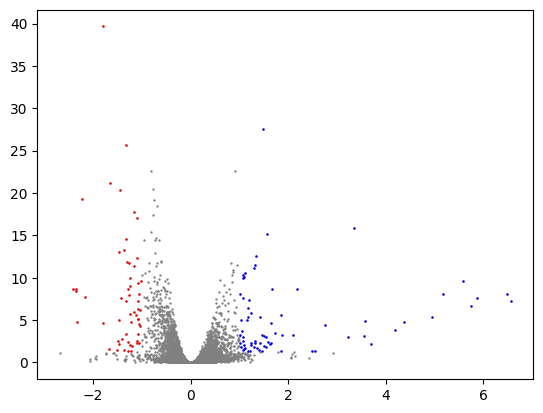

In [54]:
plt.scatter(df['log2FoldChange'], -np.log10(df['padj']), c="gray", s=0.5)
plt.scatter(listaFC_inferior, -np.log10(listapval_inferior), c="red", s=0.5)
plt.scatter(listaFC_superior, -np.log10(listapval_superior), c="blue", s=0.5)

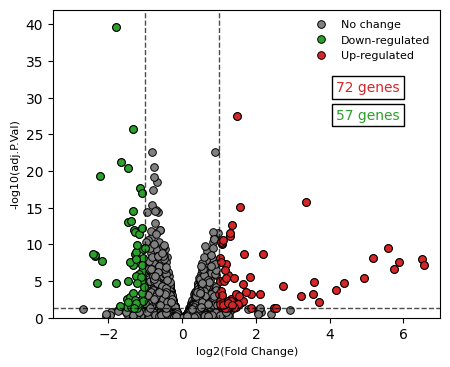

In [140]:
plots_em_x=1
plots_em_y=1
label_size=8
ticksize=10
fig, axs= plt.subplots(plots_em_y,plots_em_x, figsize=(5*plots_em_x, 4*plots_em_y))

#pontos
plt.plot(df['log2FoldChange'],-np.log10(df['padj']),lw=0,label='No change', marker='o',ms=5.5,mew=0.7, fillstyle='full',markerfacecolor='gray', mec="black")
plt.plot(listaFC_inferior, -np.log10(listapval_inferior),lw=0,label='Down-regulated',marker='o',ms=5.5,mew=0.7, fillstyle='full',markerfacecolor='C2', mec="black")
plt.plot(listaFC_superior, -np.log10(listapval_superior), lw=0,label='Up-regulated',marker='o',ms=5.5,mew=0.7, fillstyle='full',markerfacecolor='C3', mec="black")


#título dos eixos
axs.set_ylabel(r'-log10(adj.P.Val)',fontsize=label_size)
axs.set_xlabel(r'log2(Fold Change)',fontsize=label_size)

axs.legend(fontsize=label_size, frameon=False, loc= 'upper right')#,bbox_to_anchor=(0.5, 0.4))

axs.annotate('%s genes' %len(listapval_superior), xy=(0.73, 0.77),xycoords='axes fraction',
                      horizontalalignment='left', verticalalignment='top',  color='C3',
              bbox=dict(facecolor='none', edgecolor='black', boxstyle='square'))
axs.annotate('%s genes' %len(listapval_inferior), xy=(0.73, 0.68),xycoords='axes fraction',
                      horizontalalignment='left', verticalalignment='top',  color='C2',
              bbox=dict(facecolor='none', edgecolor='black', boxstyle='square'))


axs.set_xlim(-3.5, 7)  # Eixo X: -15 a +15
axs.set_ylim(0, 42)     # Eixo Y: 0 a 7

#linhas
#Linha horizontal – limite de significância estatística
plt.plot((-3.5,7),(-np.log10(limite_infeiorp),-np.log10(limite_infeiorp)), ls="--", color='black',lw=1,alpha=0.7)

# Linhas verticais – limite inferior de Fold Change
axs.plot((limite_inferior, limite_inferior),
         (-1.3, 42),
         ls="--", color='black', lw=1, alpha=0.7)

# Linha vertical – limite superior de Fold Change
axs.plot((limite_superior, limite_superior),
         (-1.3, 42),
         ls="--", color='black', lw=1, alpha=0.7)


plt.savefig('/content/volcano_manual.pdf',
            bbox_inches='tight',
            pad_inches=0.02,
            transparent=True,
            dpi=300)

In [81]:
print ('Up=',len(listapval_superior))
print ('Down=',len(listapval_inferior))
print ('No Change=',len(df['padj'])-len(listapval_inferior)-len(listapval_superior))

Up= 72
Down= 57
No Change= 13211
